<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG203 - Deep Learning**</span>

Bienvenido al curso!!!

Vamos a revisar diferentes algoritmos de <span style="color:gold">aprendizaje profundo</span> y su aplicación en Geología. <br>
Es necesario que tengas un conocimiento previo en programación con Python, álgebra lineal, estadística, geología y machine learning.


<span style="color:gold; font-size:20px">**Redes neuronales desde cero**</span>

***
- [¿Qué es una red neuronal?](#parte-1)
- [Conceptos fundamentales](#parte-2)
- [Programando una red neuronal usando Python](#parte-3)
- [En conclusión...](#parte-4)

***

In [ ]:
import sys

if sys.platform == "emscripten":
    import piplite
    await piplite.install(['numpy', 'matplotlib'])

<a id="parte-1"></a>

### <span style="color:lightgreen">**¿Qué es una red neuronal?**</span>
***

Una red neuronal es un modelo que encadena capas. En una capa densa cada neurona multiplica las entradas por pesos, suma un sesgo y aplica una función de activación. La última capa produce la salida que pide el problema.

En [PG200](pg200a_gradient_descent.ipynb) cambiábamos una pendiente y un intercepto para reducir la pérdida. Aquí seguimos la misma regla. La diferencia es que tenemos varias capas y necesitamos calcular la contribución de cada parámetro a la pérdida.

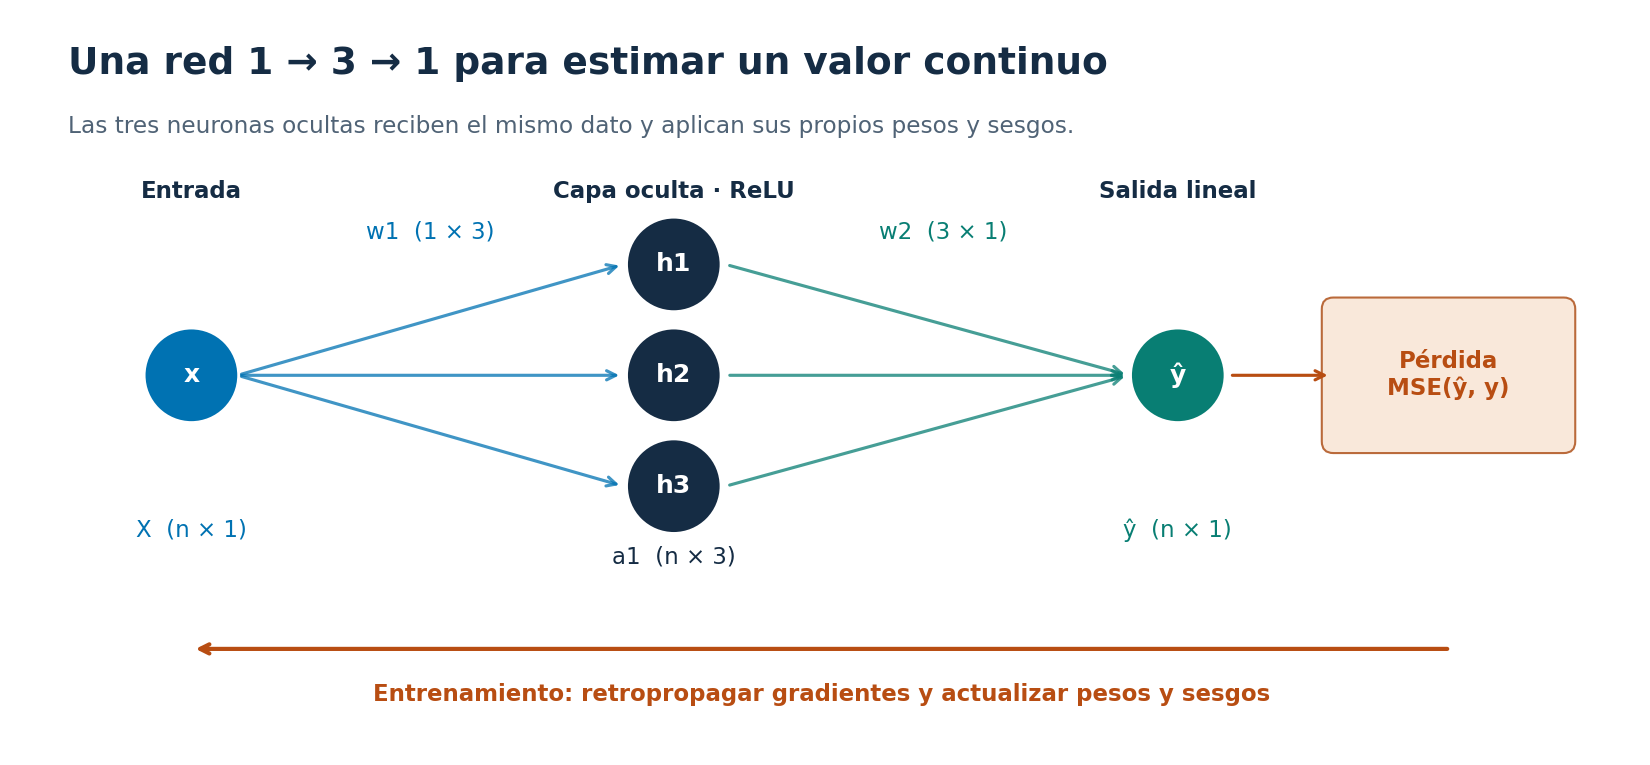

En una predicción seguimos las flechas hacia la derecha. Para aprender, la pérdida proporciona los gradientes que recorren la red hacia atrás.

---
<span style="color:gold">**Breve historia de las redes neuronales**</span>

Las redes neuronales artificiales (Artificial Neural Networks o ANN en inglés) tienen sus raíces en la década de 1940, cuando [Warren McCulloch y Walter Pitts](https://www.cs.cmu.edu/~./epxing/Class/10715/reading/McCulloch.and.Pitts.pdf) presentaron el primer modelo teórico de una neurona artificial. Inspirados en el funcionamiento del cerebro, su trabajo proponía una forma de <span style="color:#43c6ac">simular el proceso de toma de decisiones a través de una red de unidades interconectadas</span>. 

En 1958, [Frank Rosenblatt](https://www.ling.upenn.edu/courses/cogs501/Rosenblatt1958.pdf) desarrolló el perceptrón, la primera implementación práctica de una red neuronal simple, la cual podía aprender a clasificar patrones mediante ajustes en los pesos de sus conexiones. Aunque este modelo fue limitado en cuanto a lo que podía aprender, abrió el camino para investigaciones posteriores.

En las décadas siguientes, el entusiasmo por las redes neuronales fluctuó. Durante los 1970 y 1980, trabajos de [Rumelhart, Hinton y Williams](https://www.nature.com/articles/323533a0) y [Yann LeCun](https://yann.lecun.com/exdb/publis/pdf/lecun-89e.pdf) impulsaron nuevas técnicas y arquitecturas, incluyendo la <span style="color:gold">retropropagación</span>, un método que permitió entrenar redes más profundas y complejas, marcando el comienzo de una nueva era. Aun así, las limitaciones computacionales de la época frenaron su progreso hasta el siglo XXI.

Con los avances en hardware (como las GPU) y la disponibilidad de grandes conjuntos de datos, las redes neuronales vivieron un renacimiento. En 2012, una red profunda (deep neural network) entrenada por [Alex Krizhevsky, Ilya Sutskever y Geoffrey Hinton](https://proceedings.neurips.cc/paper_files/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf) ganó la competencia de reconocimiento de imágenes ImageNet, destacando las redes neuronales profundas como una herramienta poderosa para resolver problemas complejos.

---

En geología podemos elegir la arquitectura según cómo se organizan los datos.

| Arquitectura | ¿Qué recibe? | Ejemplo |
| --- | --- | --- |
| Capas densas (MLP) | Una fila de características | Estimar una propiedad de roca a partir de ensayos |
| Red convolucional (CNN) | Una grilla con estructura espacial | Identificar texturas en fotomicrografías |
| Red recurrente o atención (Transformer) | Una secuencia ordenada o con posiciones | Interpretar intervalos consecutivos de un registro |
| Autoencoder | Una entrada que el modelo intenta reconstruir | Comprimir respuestas de varios sensores |

La misma arquitectura puede servir con objetivos distintos. En regresión usamos una salida continua y una pérdida como MSE. Para dos clases podemos convertir un puntaje con la sigmoide de [PG201](pg201b_logreg.ipynb) y entrenar con entropía cruzada. Para varias clases, softmax convierte varios puntajes en valores que suman uno. En un autoencoder, el objetivo de reconstrucción sale de la propia entrada.

<a id="parte-2"></a>

### <span style="color:lightgreen">**Conceptos fundamentales**</span>
***

- **Pesos y sesgos.** Son los parámetros que cambia el optimizador. El sesgo desplaza la activación. El efecto de un peso depende de las demás capas y de la entrada.
- **Activación.** Sin una activación no lineal entre capas, encadenar transformaciones afines sigue dando una sola transformación afín. ReLU permite que la pendiente cambie según la entrada.
- **Pérdida.** Mide el desacuerdo entre salida y objetivo. En este caso, MSE promedia las diferencias al cuadrado.
- **Retropropagación.** Usa la regla de la cadena para calcular derivadas. Luego el optimizador aplica el paso de actualización. En este notebook usamos descenso del gradiente.
- **Época y lote.** Una época recorre el conjunto de entrenamiento una vez. Aquí el lote contiene todo el conjunto, así que hay un paso por época. Con minilotes puede haber varios.
- **Hiperparámetros.** Elegimos el ancho de la capa, la tasa de aprendizaje y el número máximo de épocas. Los pesos cambian dentro del bucle de entrenamiento.

En redes profundas, inicializaciones como [Xavier](https://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf) y [He](https://arxiv.org/abs/1502.01852) ayudan a controlar las magnitudes iniciales. Dropout cambia las activaciones durante el entrenamiento. La normalización por lotes utiliza estadísticas del lote al entrenar y estadísticas acumuladas al inferir. Aquí veremos cómo la validación nos ayuda a elegir la época y el ancho.

<a id="parte-3"></a>

### <span style="color:lightgreen">**Programando una red neuronal usando Python**</span>
***

Mantendremos visible el cálculo con NumPy. Vamos a separar filas, inicializar parámetros, calcular predicciones y pérdida, derivar un paso y repetirlo. Elegiremos un punto de control usando validación. Al final evaluaremos ese punto de control en prueba y lo compararemos con una recta.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

<span style="color:gold">**Preparación de datos**</span>

Conservamos el caso lineal $y=3x+4$ con ruido y creamos un segundo objetivo con curvatura para explorar qué aporta ReLU. Las dos tareas usan las mismas entradas y la misma división. Una fila representa una observación sintética.

In [ ]:
rng = np.random.default_rng(42)
X = rng.normal(size=(100, 1))
ruido = 0.25 * rng.normal(size=X.shape)
y = 3 * X + 4 + ruido
y_curva = 2 + 1.2 * X ** 2 + ruido

orden = rng.permutation(len(X))
entrenamiento, validacion, prueba = orden[:60], orden[60:80], orden[80:]
print(f"X: {X.shape} | y: {y.shape}")
print(f"Ajuste: {len(entrenamiento)} | Validación: {len(validacion)} | Prueba: {len(prueba)}")

Primero miramos los **datos de entrenamiento**. Anticipa en cuál de las dos tareas una recta será una referencia difícil de mejorar.

| Filas | En este notebook |
| --- | --- |
| `entrenamiento` | Calculan gradientes y ajustan la recta de referencia |
| `validacion` | Determinan qué época y ancho conservamos |
| `prueba` | Comparan la recta y la red elegida en filas reservadas |

Si necesitáramos reescalar entradas o imputar valores, aprenderíamos esos parámetros solo con entrenamiento y aplicaríamos la misma transformación a los otros dos conjuntos.

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True)
for ax, valores, titulo in zip(ejes, [y, y_curva], ["Relación lineal", "Relación curva"]):
    ax.scatter(X[entrenamiento, 0], valores[entrenamiento, 0], color="#0072B2", s=22, alpha=.7)
    ax.set(title=titulo, xlabel="Entrada x")
    ax.grid(alpha=.22)
ejes[0].set_ylabel("Objetivo y")
fig.tight_layout()
plt.show()

<span style="color:gold">**Arquitectura de la red neuronal**</span>

Empezamos con la red del diagrama: una entrada, tres unidades ocultas y una salida. Los pesos iniciales usan un generador con semilla explícita. Llamar a `inicializar` con la misma semilla y ancho empieza de nuevo en el mismo punto. Para continuar un ajuste debemos pasar los parámetros que ya obtuvimos.

In [ ]:
def inicializar(ancho=3, semilla=42):
    rng_pesos = np.random.default_rng(semilla)
    w1 = rng_pesos.normal(0, 0.8, size=(1, ancho))
    b1 = rng_pesos.uniform(-0.5, 0.5, size=(1, ancho))
    w2 = rng_pesos.normal(0, 1 / np.sqrt(ancho), size=(ancho, 1))
    b2 = np.zeros((1, 1))
    return w1, b1, w2, b2


inicial = inicializar()
for nombre, p in zip(["w1", "b1", "w2", "b2"], inicial):
    print(nombre, p.shape)

La función ReLU es ampliamente utilizada en las capas ocultas de redes neuronales. Su fórmula es:



$$
\Large \text{ReLU}(x) = \text{max}(0, x)
$$



Esta función activa solo las neuronas con valores positivos, introduciendo no linealidad y permitiendo que la red aprenda representaciones más complejas.

In [ ]:
# Función de activación: ReLU
def relu(x):
    return np.maximum(0, x)

Para valores positivos, ReLU conserva el valor y su derivada es 1. Para valores negativos la salida y la derivada son 0. En cero hay un quiebre y elegimos usar 0 en el código.

In [ ]:
# Derivada de ReLU
def relu_derivative(x):
    return np.where(x > 0, 1, 0)

La salida de regresión usa la identidad. El resultado puede tomar cualquier valor real. Si el objetivo físico tiene límites, habría que comprobar el rango de predicciones o cambiar el modelo.

<span style="color:gold">**Propagación hacia adelante**</span>

- `X @ w1 + b1` multiplica $(n,1)$ por $(1,3)$ y suma el mismo sesgo a cada fila.
- `relu(z1)` conserva la forma $(n,3)$ y cambia los valores negativos a cero.
- `a1 @ w2 + b2` combina esas tres activaciones y devuelve $(n,1)$.

Cada fila mantiene su orden y representa la misma observación hasta la salida.

In [ ]:
def forward(X, parametros):
    w1, b1, w2, b2 = parametros
    z1 = X @ w1 + b1
    a1 = relu(z1)
    output = a1 @ w2 + b2
    return z1, a1, output


fila = entrenamiento[:1]
X_fila, y_fila = X[fila], y[fila]
z1, a1, output = forward(X_fila, inicial)
print("Entrada:", X_fila.round(3), "Objetivo:", y_fila.round(3))
print("Antes de ReLU:", z1.round(3), "Después de ReLU:", a1.round(3))
print("Predicción:", output.round(3))

Necesitamos de una función de pérdida para medir la precisión de nuestras predicciones. 

Usaremos el **Error Cuadrático Medio** (**MSE**, por sus siglas en inglés), una métrica común en problemas de regresión. 

La función `mse_loss` toma dos argumentos: `y_true`, que son los valores reales, y `y_pred`, que son los valores predichos por el modelo. Calcula el error al encontrar la diferencia entre `y_true` y `y_pred`, elevando al cuadrado cada diferencia para penalizar errores grandes, y luego promedia estos valores. Esta métrica nos da una medida de cuán lejos están las predicciones de los valores reales, lo cual es útil para ajustar los pesos durante el entrenamiento.

In [ ]:
# Función de perdida
def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

<span style="color:gold">**Propagación hacia atrás**</span>

La derivada de MSE con respecto a la salida es $2(\hat y-y)/n$ para una sola salida por fila. Para saber cómo cambiar esa salida, `a1.T @ d_output` suma los aportes a cada peso de la última capa.

Para pasar a la capa oculta hacemos `d_output @ w2.T`. Luego multiplicamos por la derivada de ReLU en cada posición. Una neurona apagada en esta fila no aporta gradiente para sus parámetros ocultos. Al terminar, cada derivada tiene la forma de su parámetro.

In [ ]:
def backward(X, y, z1, a1, output, parametros):
    w2 = parametros[2]
    d_output = 2 * (output - y) / y.size
    dw2 = a1.T @ d_output
    db2 = d_output.sum(axis=0, keepdims=True)

    d_hidden = (d_output @ w2.T) * relu_derivative(z1)
    dw1 = X.T @ d_hidden
    db1 = d_hidden.sum(axis=0, keepdims=True)
    return dw1, db1, dw2, db2


def actualizar(parametros, gradientes, tasa):
    return tuple(p - tasa * g for p, g in zip(parametros, gradientes))

**Un paso con una fila.** Lee el gradiente del sesgo de salida. ¿Qué signo tendrá si la predicción queda por debajo de la referencia? Después del paso, compara la pérdida de la misma fila.

In [ ]:
gradientes = backward(X_fila, y_fila, z1, a1, output, inicial)
tasa_demo = 0.03
despues = actualizar(inicial, gradientes, tasa_demo)
print(f"Gradiente de b2: {gradientes[-1].item():.4f}")
print(f"b2 antes: {inicial[-1].item():.4f} | b2 después: {despues[-1].item():.4f}")
print(f"MSE antes: {mse_loss(y_fila, output):.4f}")
print(f"MSE después: {mse_loss(y_fila, forward(X_fila, despues)[-1]):.4f}")

<span style="color:gold">**Entrenamiento de la red neuronal**</span>

Cada época actualiza los parámetros con entrenamiento. Evaluamos el resultado en validación sin calcular gradientes con esas filas. Guardamos los parámetros de la época con menor pérdida de validación, aunque sigamos calculando la curva hasta el máximo de épocas. Cada actualización crea matrices nuevas, así que el punto de control queda disponible.

In [ ]:
def entrenar(X_train, y_train, X_val, y_val, parametros, epocas=700, tasa=0.045):
    historial = []
    menor_perdida = np.inf
    mejor = parametros
    mejor_epoca = 0
    for epoca in range(1, epocas + 1):
        z1, a1, salida = forward(X_train, parametros)
        gradientes = backward(X_train, y_train, z1, a1, salida, parametros)
        parametros = actualizar(parametros, gradientes, tasa)
        loss_train = mse_loss(y_train, forward(X_train, parametros)[-1])
        loss_val = mse_loss(y_val, forward(X_val, parametros)[-1])
        historial.append((loss_train, loss_val))
        if loss_val < menor_perdida:
            menor_perdida = loss_val
            mejor, mejor_epoca = parametros, epoca
    return mejor, mejor_epoca, np.array(historial)


tareas = {"Lineal": y, "Curva": y_curva}
candidatos = {}
for tarea, objetivo in tareas.items():
    for ancho in (3, 12):
        candidatos[tarea, ancho] = entrenar(
            X[entrenamiento], objetivo[entrenamiento],
            X[validacion], objetivo[validacion], inicializar(ancho),
        )

elegidos = {
    tarea: min((3, 12), key=lambda ancho: candidatos[tarea, ancho][2][:, 1].min())
    for tarea in tareas
}
for tarea, ancho in elegidos.items():
    _, epoca, historia = candidatos[tarea, ancho]
    print(f"{tarea}: {ancho} neuronas | época {epoca} | MSE val. {historia[epoca-1, 1]:.3f}")

La pérdida puede seguir bajando en ajuste mientras sube en validación. El punto marcado indica dónde elegimos los parámetros. Una sola división sintética ilustra el flujo. En un estudio de pozos o imágenes reservaríamos pozos o especímenes completos.

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharex=True)
for ax, (tarea, ancho) in zip(ejes, elegidos.items()):
    _, epoca, historia = candidatos[tarea, ancho]
    pasos = np.arange(1, len(historia) + 1)
    ax.semilogy(pasos, historia[:, 0], color="#0072B2", label="Entrenamiento")
    ax.semilogy(pasos, historia[:, 1], color="#B84D12", label="Validación")
    ax.axvline(epoca, color="#087E73", ls="--", label=f"Época elegida: {epoca}")
    ax.set(title=f"{tarea} · {ancho} neuronas", xlabel="Época", ylabel="MSE (escala log)")
    ax.legend(fontsize=9)
    ax.grid(alpha=.20)
fig.tight_layout()
plt.show()

<span style="color:gold">**Evaluación del modelo**</span>

Ahora usamos las filas de prueba por primera vez. La recta de referencia se ajusta a las mismas filas de entrenamiento que la red. `lstsq` elige intercepto y pendiente por mínimos cuadrados. Calculamos el RMSE en unidades de $y$ para cada modelo.

In [ ]:
def matriz_lineal(X):
    return np.column_stack([np.ones(len(X)), X[:, 0]])


rectas, resultados = {}, {}
X_test = X[prueba]
for tarea, objetivo in tareas.items():
    coef, *_ = np.linalg.lstsq(matriz_lineal(X[entrenamiento]), objetivo[entrenamiento], rcond=None)
    rectas[tarea] = coef
    parametros, _, _ = candidatos[tarea, elegidos[tarea]]
    pred_red = forward(X_test, parametros)[-1]
    pred_recta = matriz_lineal(X_test) @ coef
    rmse_red = np.sqrt(mse_loss(objetivo[prueba], pred_red))
    rmse_recta = np.sqrt(mse_loss(objetivo[prueba], pred_recta))
    resultados[tarea] = (rmse_recta, rmse_red)
    print(f"{tarea} | RMSE recta: {rmse_recta:.3f} | RMSE red: {rmse_red:.3f}")

Usamos el mismo rango horizontal para dibujar ambos modelos. Las curvas son las predicciones para una grilla ordenada. Los puntos corresponden a observaciones reservadas.

In [ ]:
malla = np.linspace(X.min(), X.max(), 250).reshape(-1, 1)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True)
for ax, (tarea, objetivo) in zip(ejes, tareas.items()):
    parametros, _, _ = candidatos[tarea, elegidos[tarea]]
    rmse_recta, rmse_red = resultados[tarea]
    ax.scatter(X[prueba, 0], objetivo[prueba, 0], color="#152C44", s=28, label="Observaciones de prueba")
    ax.plot(malla[:, 0], matriz_lineal(malla) @ rectas[tarea], "--", color="#0072B2",
            label=f"Recta · RMSE {rmse_recta:.2f}")
    ax.plot(malla[:, 0], forward(malla, parametros)[-1], color="#B84D12",
            label=f"Red · RMSE {rmse_red:.2f}")
    ax.set(title=f"Tarea {tarea.lower()}", xlabel="Entrada x", ylabel="Objetivo y")
    ax.legend(fontsize=9)
    ax.grid(alpha=.22)
fig.tight_layout()
plt.show()

La recta y la red tienen el mismo acceso a los datos. En la segunda tarea la red puede cambiar de pendiente y aproximar la curvatura mediante tramos. En la primera, revisa cuánto aporta esa flexibilidad cuando una recta ya coincide con el proceso que generó los datos.

Para pasar de una práctica a un estudio real, guarda la definición de las características y unidades, la división por grupos, la semilla y el punto de control. Al desplegar volvemos a ejecutar `forward` con los parámetros elegidos. Aplica las mismas transformaciones aprendidas en entrenamiento si las hubo.

<a id="parte-4"></a>

### <span style="color:lightgreen">**En conclusión...**</span>
***

**Comprueba tu lectura.** Si una activación oculta es cero, sigue su contribución a la salida y al gradiente en esa fila. Después, explica por qué elegimos la época por validación y qué evidencia perderíamos si consultáramos la prueba para elegir el ancho.

**Práctica con IA.** Pide una versión que use minilotes. Comprueba que cada época recorra solo entrenamiento, que las formas de los gradientes coincidan con las de los pesos y que los datos de validación y prueba se usen únicamente para medir. Compara las curvas con el bucle original.

[Referencia sobre redes densas supervisadas](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)

---